In [1]:
from pathlib import Path

import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from torchvision.models import (
    convnext_base,
    ConvNeXt_Base_Weights
)

from tqdm.auto import tqdm

In [2]:
from pathlib import Path

DATA_DIR = Path("/kaggle/input/datasets/overgame1234/sid-set-processed-224")

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

print("Train:", TRAIN_DIR.exists())
print("Val:", VAL_DIR.exists())
print("Test:", TEST_DIR.exists())

Train: True
Val: True
Test: True


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [4]:
train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=transform
)

print("Classes:", train_dataset.classes)
print("Mapping:", train_dataset.class_to_idx)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['full_synthetic', 'real', 'tampered']
Mapping: {'full_synthetic': 0, 'real': 1, 'tampered': 2}
Train: 2783
Validation: 596
Test: 597


In [5]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("DataLoaders recreated successfully.")

DataLoaders recreated successfully.


In [6]:
weights = ConvNeXt_Base_Weights.IMAGENET1K_V1

model = convnext_base(
    weights=weights
)

Downloading: "https://download.pytorch.org/models/convnext_base-6075fbad.pth" to /root/.cache/torch/hub/checkpoints/convnext_base-6075fbad.pth


100%|██████████| 338M/338M [00:01<00:00, 216MB/s]  


In [7]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [8]:
model = model.to(device)

In [9]:
num_classes = len(train_dataset.classes)

in_features = model.classifier[2].in_features

model.classifier[2] = nn.Linear(
    in_features,
    num_classes
)

model = model.to(device)

print(model.classifier)

Sequential(
  (0): LayerNorm2d((1024,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=1024, out_features=3, bias=True)
)


In [10]:
for param in model.parameters():
    param.requires_grad = False

# افتح آخر stage فقط
for param in model.features[-2:].parameters():
    param.requires_grad = True

# افتح classifier
for param in model.classifier.parameters():
    param.requires_grad = True

In [ ]:
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-5,
    weight_decay=1e-4
)

In [11]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 87569539
Trainable parameters: 87569539


In [12]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

In [13]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [14]:
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

In [15]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        loader,
        desc="Training"
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item()
            * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [16]:
def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        progress = tqdm(
            loader,
            desc="Validation"
        )

        for images, labels in progress:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            running_loss += (
                loss.item()
                * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [17]:
CHECKPOINT_DIR = Path(
    "/kaggle/working/checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(CHECKPOINT_DIR)

/kaggle/working/checkpoints


In [18]:
EPOCHS = 15
PATIENCE = 4

best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

In [19]:
for epoch in range(EPOCHS):

    print()
    print(
        f"Epoch {epoch + 1}/{EPOCHS}"
    )

    print("=" * 60)

    # --------------------
    # TRAIN
    # --------------------

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        device
    )

    # --------------------
    # VALIDATION
    # --------------------

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    # Scheduler
    scheduler.step(val_loss)

    # History
    history["train_loss"].append(
        train_loss
    )

    history["train_acc"].append(
        train_acc
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_acc"].append(
        val_acc
    )

    print()
    print(
        f"Train Loss: {train_loss:.4f}"
    )

    print(
        f"Train Accuracy: {train_acc:.2%}"
    )

    print(
        f"Val Loss: {val_loss:.4f}"
    )

    print(
        f"Val Accuracy: {val_acc:.2%}"
    )

    print(
        "Learning Rate:",
        optimizer.param_groups[0]["lr"]
    )

    # ==============================
    # CHECKPOINT EVERY EPOCH
    # ==============================

    checkpoint = {
        "epoch": epoch + 1,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "train_loss":
            train_loss,

        "train_acc":
            train_acc,

        "val_loss":
            val_loss,

        "val_acc":
            val_acc,

        "classes":
            train_dataset.classes,

        "class_to_idx":
            train_dataset.class_to_idx
    }

    checkpoint_path = (
        CHECKPOINT_DIR
        / f"checkpoint_epoch_{epoch + 1}.pth"
    )

    torch.save(
        checkpoint,
        checkpoint_path
    )

    print(
        "Checkpoint saved:",
        checkpoint_path
    )

    # ==============================
    # BEST MODEL
    # ==============================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            checkpoint,
            CHECKPOINT_DIR / "best_model.pth"
        )

        print(
            "Best model updated."
        )

    else:

        epochs_without_improvement += 1

        print(
            "No improvement:",
            epochs_without_improvement,
            "/",
            PATIENCE
        )

    # ==============================
    # EARLY STOPPING
    # ==============================

    if epochs_without_improvement >= PATIENCE:

        print()
        print(
            "Early stopping."
        )

        break


Epoch 1/15


Training:   0%|          | 0/174 [00:00<?, ?it/s]

Validation:   0%|          | 0/38 [00:00<?, ?it/s]


Train Loss: 0.9213
Train Accuracy: 58.68%
Val Loss: 0.6367
Val Accuracy: 77.68%
Learning Rate: 1e-05
Checkpoint saved: /kaggle/working/checkpoints/checkpoint_epoch_1.pth
Best model updated.

Epoch 2/15


Training:   0%|          | 0/174 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/38 [00:00<?, ?it/s]


Train Loss: 0.0556
Train Accuracy: 99.07%
Val Loss: 0.3199
Val Accuracy: 87.25%
Learning Rate: 5e-06
Checkpoint saved: /kaggle/working/checkpoints/checkpoint_epoch_9.pth
No improvement: 3 / 4

Epoch 10/15


Training:   0%|          | 0/174 [00:00<?, ?it/s]

Validation:   0%|          | 0/38 [00:00<?, ?it/s]


Train Loss: 0.0358
Train Accuracy: 99.60%
Val Loss: 0.2973
Val Accuracy: 88.93%
Learning Rate: 5e-06
Checkpoint saved: /kaggle/working/checkpoints/checkpoint_epoch_10.pth
No improvement: 4 / 4

Early stopping.


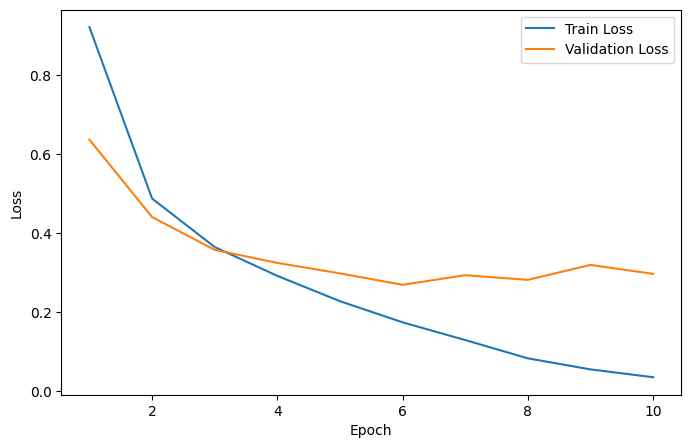

In [20]:
import matplotlib.pyplot as plt

epochs = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_acc"],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

In [ ]:
best_checkpoint = torch.load(
    CHECKPOINT_DIR / "best_model.pth",
    map_location=device
)

model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

print(
    "Best epoch:",
    best_checkpoint["epoch"]
)

print(
    "Best validation loss:",
    best_checkpoint["val_loss"]
)

print(
    "Best validation accuracy:",
    f"{best_checkpoint['val_acc']:.2%}"
)